# 06 · Companies, not tickers: the security master

Tickers are not identifiers. They get **renamed** (Facebook traded as `FB` until 2022-06-08,
then as `META`) and **reused** (`FB` has been a ProShares ETF since 2025-06-26; `META` was a
Roundhill ETF in 2021-22). Anything keyed by ticker can silently mix companies.

The security master gives every (ticker, day) in the bars a stable `security_id`. It is built
by `uv run subspace identity build` (design: `docs/decisions/0002-security-master.md`) and
refreshed by the nightly sync. This notebook shows how to use it and what it found.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import polars as pl
from massive_subspace_stream import Store
from subspace_probe import style

style()
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_fmt_str_lengths(45)
store = Store()

## 1 · The problem in one chart

Asking for `FB` by ticker returns everything that ever traded as `FB`. The `security_id`
column tells the two securities apart:

In [2]:
fb = store.bars("FB", start="2012-01-01")
fb.group_by("security_id").agg(pl.col("date").min().alias("first"), pl.col("date").max().alias("last"),
                               pl.len().alias("days"), pl.col("close").last().alias("last_close")).sort("first")

security_id,first,last,days,last_close
str,date,date,u32,f64
"""BBG000MM2P62""",2012-05-18,2022-06-08,2531,196.64
"""BBG01VRMNFB1""",2025-06-26,2026-10-30,340,45.4282


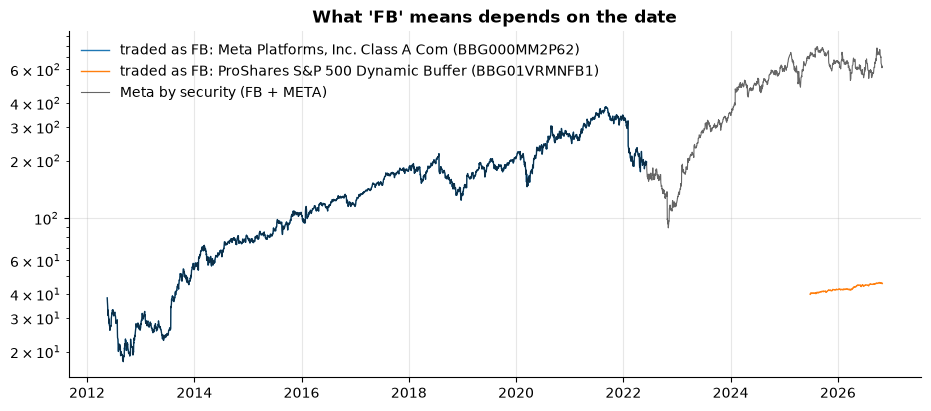

In [3]:
meta = store.bars("META", start="2012-01-01", by="security")
names = dict(store.securities(tickers="FB").select("security_id", "name").iter_rows())
fig, ax = plt.subplots()
for (sid,), g in fb.group_by("security_id", maintain_order=True):
    ax.plot(g["date"].to_list(), g["close"].to_list(), lw=1, label=f"traded as FB: {names[sid][:32]} ({sid})")
ax.plot(meta["date"].to_list(), meta["close"].to_list(), lw=0.8, color="black", alpha=0.6,
        label="Meta by security (FB + META)")
ax.set_yscale("log")
ax.set_title("What 'FB' means depends on the date")
ax.legend();

`by="security"` returns one company's whole history across its tickers. A ticker is resolved
as of `end` (default: today), so use the current ticker (`META`) or pass a `security_id`.

In [4]:
meta.group_by("ticker", maintain_order=True).agg(pl.col("date").min().alias("from"), pl.col("date").max().alias("to"),
                                                 pl.col("security_id").first())

ticker,from,to,security_id
str,date,date,str
"""FB""",2012-05-18,2022-06-08,"""BBG000MM2P62"""
"""META""",2022-06-09,2026-10-30,"""BBG000MM2P62"""


## 2 · Looking things up

In [5]:
store.resolve(["FB", "META", "TWTR", "GOOG", "GOOGL"], on="2015-06-30")

ticker,date,security_id,name,type
str,date,str,str,str
"""FB""",2015-06-30,"""BBG000MM2P62""","""Meta Platforms, Inc. Class A Common Stock""","""CS"""
"""META""",2015-06-30,null,null,null
"""TWTR""",2015-06-30,"""BBG000H6HNW3""","""Twitter, Inc.""","""CS"""
"""GOOG""",2015-06-30,"""BBG009S3NB30""","""Alphabet Inc. Class C Capital Stock""","""CS"""
"""GOOGL""",2015-06-30,"""BBG009S39JX6""","""Alphabet Inc. Class A Common Stock""","""CS"""


In [6]:
store.securities(tickers=["FB", "META"]).select("security_id", "name", "type", "tickers", "first_trade", "last_trade", "active")

security_id,name,type,tickers,first_trade,last_trade,active
str,str,str,list[str],date,date,bool
"""BBG000MM2P62""","""Meta Platforms, Inc. Class A Common Stock""","""CS""","[""FB"", ""META""]",2012-05-18,2026-10-30,true
"""BBG011J1MN62""","""Roundhill Metaverse ETF""","""ETF""","[""META"", ""METV""]",2021-06-30,2026-10-30,true
"""BBG01VRMNFB1""","""ProShares S&P 500 Dynamic Buffer ETF""","""ETF""","[""FB""]",2025-06-26,2026-10-30,true


In [7]:
store.security_master(["FB", "META"]).select("ticker", "valid_from", "valid_to", "security_id", "name", "method", "linked_by")

ticker,valid_from,valid_to,security_id,name,method,linked_by
str,date,date,str,str,str,str
"""FB""",2012-05-18,2022-06-08,"""BBG000MM2P62""","""Meta Platforms, Inc. Class A Common Stock""","""snapshot""",null
"""FB""",2025-06-26,null,"""BBG01VRMNFB1""","""ProShares S&P 500 Dynamic Buffer ETF""","""snapshot""",null
"""META""",2021-06-30,2022-01-28,"""BBG011J1MN62""","""Roundhill Ball Metaverse ETF""","""snapshot""",null
"""META""",2022-06-09,null,"""BBG000MM2P62""","""Meta Platforms, Inc. Class A Common Stock""","""snapshot""","""figi"""


## 3 · What the build found

Each ticker's trading days are split into episodes at gaps of more than 30 days, then into
segments wherever the identity changes (month-end snapshots that disagree, located to the day
with dated lookups). Segments are linked into securities by equal FIGI, the same ticker across a
gap, a CIK hand-off between two tickers, or a manual override.

In [8]:
master = store.security_master()
secs = store.securities()
print(f"{master.height:,} ticker windows -> {secs.height:,} securities")
print(f"tickers that meant more than one security: {master.group_by('ticker').agg(pl.col('security_id').n_unique()).filter(pl.col('security_id') > 1).height:,}")
print(f"securities that used more than one ticker: {secs.filter(pl.col('tickers').list.unique().list.len() > 1).height:,}")
pl.concat([
    master.group_by("method").len().rename({"method": "value"}).with_columns(pl.lit("how the window was identified").alias("what")),
    master.group_by("linked_by").len().rename({"linked_by": "value"}).with_columns(pl.lit("how it joined its security").alias("what")),
    secs.group_by("id_source").len().rename({"id_source": "value"}).with_columns(pl.lit("where the id comes from").alias("what")),
]).select("what", "value", "len").sort("what", "len", descending=[False, True])

48,808 ticker windows -> 41,455 securities
tickers that meant more than one security: 4,688
securities that used more than one ticker: 3,061


what,value,len
str,str,u32
"""how it joined its security""",null,41495
"""how it joined its security""","""figi""",3416
"""how it joined its security""","""ticker_gap""",2287
"""how it joined its security""","""cik_handoff""",1608
"""how it joined its security""","""override""",2
"""how the window was identified""","""snapshot""",42711
"""how the window was identified""","""lookup""",2957
"""how the window was identified""","""unresolved""",2416
"""how the window was identified""","""bisect""",723


Old reference data rarely has FIGIs, so many delisted securities get a CIK- or symbol-based id
(`CIK:<cik>:<ticker>`, `SYM:<ticker>:<first trade>`). The ids are stable across rebuilds.

A few renames found by the CIK hand-off rule (one ticker stops, another with the same CIK starts
within a week, at a continuous price):

In [9]:
handoffs = master.filter(pl.col("linked_by") == "cik_handoff").select("security_id").unique()
(master.filter(pl.col("security_id").is_in(handoffs["security_id"].to_list()))
 .sort("security_id", "valid_from")
 .group_by("security_id", maintain_order=True)
 .agg(pl.col("ticker").str.join(" -> ").alias("tickers"), pl.col("name").last(), pl.col("valid_from").min().alias("since"))
 .filter(pl.col("since") > date(2015, 1, 1)).head(12))

security_id,tickers,name,since
str,str,str,date
"""BBG000BD7CF8""","""APHB -> ARMP""","""Armata Pharmaceuticals, Inc. Common Stock""",2015-08-21
"""BBG000BG3J79""","""ITUS -> ANIX""","""Anixa Biosciences, Inc.""",2015-07-10
"""BBG000BR52Q9""","""TPNL -> PAYS""","""Paysign, Inc. Common Stock""",2018-08-10
"""BBG000CMD5D7""","""CVLB -> LFMD""","""LifeMD, Inc. Common Stock""",2020-12-10
"""BBG000CX93B5""","""CCNI -> HQI""","""HireQuest, Inc. Common Stock (DE)""",2018-06-06
"""BBG000CZCGG2""","""SNBP -> PBLA""","""Panbela Therapeutics, Inc. Common Stock""",2020-08-28
"""BBG000DVFGS4""","""AUXO -> CTEK""","""CynergisTek, Inc.""",2017-02-14
"""BBG000FTLBV7""","""LBIO -> IOVA""","""Iovance Biotherapeutics, Inc. Common Stock""",2015-02-26
"""BBG000GMZP09""","""TPIV -> MRKR""","""Marker Therapeutics, Inc. Common Stock""",2016-11-08


## 4 · Known cases

`subspace identity check` runs these regression cases (plus coverage checks) after every build:

In [10]:
cases = [
    ("FB in 2015 is Meta", "FB", "2015-06-30", "META", "2024-06-28"),
    ("FB in 2026 is not Meta", "FB", "2026-01-30", "META", "2024-06-28"),
    ("META in 2021 was another ETF", "META", "2021-09-30", "META", "2024-06-28"),
    ("TWTR: Tweeter vs Twitter", "TWTR", "2005-06-30", "TWTR", "2015-06-30"),
    ("GOOG before 2014-04-03 is today's GOOGL", "GOOG", "2010-06-30", "GOOGL", "2020-06-30"),
    ("UTX continues as RTX", "UTX", "2010-06-30", "RTX", "2022-06-30"),
]
rows = []
for desc, t1, d1, t2, d2 in cases:
    a = store.resolve(t1, on=d1)["security_id"][0]
    b = store.resolve(t2, on=d2)["security_id"][0]
    rows.append((desc, f"{t1} {d1}", a, f"{t2} {d2}", b, a == b))
pl.DataFrame(rows, schema=["case", "first", "id", "second", "id_2", "same_security"], orient="row")

case,first,id,second,id_2,same_security
str,str,str,str,str,bool
"""FB in 2015 is Meta""","""FB 2015-06-30""","""BBG000MM2P62""","""META 2024-06-28""","""BBG000MM2P62""",true
"""FB in 2026 is not Meta""","""FB 2026-01-30""","""BBG01VRMNFB1""","""META 2024-06-28""","""BBG000MM2P62""",false
"""META in 2021 was another ETF""","""META 2021-09-30""","""BBG011J1MN62""","""META 2024-06-28""","""BBG000MM2P62""",false
"""TWTR: Tweeter vs Twitter""","""TWTR 2005-06-30""","""CIK:0001060390:TWTR""","""TWTR 2015-06-30""","""BBG000H6HNW3""",false
"""GOOG before 2014-04-03 is today's GOOGL""","""GOOG 2010-06-30""","""BBG009S39JX6""","""GOOGL 2020-06-30""","""BBG009S39JX6""",true
"""UTX continues as RTX""","""UTX 2010-06-30""","""BBG000LZL665""","""RTX 2022-06-30""","""BBG000LZL665""",true


## 5 · Adjustment follows the security

Massive files a company's past splits and dividends under its *current* ticker, sometimes also
under the old one. With the master, `adjust=` uses actions mapped to securities and recomputes
dividend factors per security. Before, the ProShares ETF's 2025-26 dividends were applied to
Facebook's 2012-2022 prices because both traded as `FB`:

In [11]:
fb_2020 = store.bars("FB", start="2020-01-02", end="2020-01-02", adjust="all")
fb_2020.select("ticker", "date", "security_id", "close", "split_factor", "div_factor")

ticker,date,security_id,close,split_factor,div_factor
str,date,str,f64,f64,f64
"""FB""",2020-01-02,"""BBG000MM2P62""",207.789859,1.0,0.990513


The factor now comes from Meta's own dividends (paid as `META` since 2024), and the ETF's
dividends only touch the ETF.

## 6 · Point-in-time universe

`universe(day)` maps each traded ticker to its security that day, with attributes from the
nearest month-end snapshot. On 2015-06-30, `FB` is Facebook's common stock, not today's ETF:

In [12]:
store.universe("2015-06-30").filter(pl.col("ticker").is_in(["FB", "TWTR", "GOOG", "GOOGL", "META"]))

ticker,close,volume,security_id,name,type,primary_exchange,active,composite_figi,cik
str,f64,f64,str,str,str,str,bool,str,str
"""FB""",85.765,2.3027325e7,"""BBG000MM2P62""","""FACEBOOK INC CL A COM STK (DE)""","""CS""","""XNAS""",true,"""BBG000MM2P62""","""0001326801"""
"""GOOG""",520.51,2.235295e6,"""BBG009S3NB30""","""GOOGLE INC CLASS C""","""CS""","""XNAS""",true,"""BBG009S3NB30""","""0001288776"""
"""GOOGL""",540.04,1.725164e6,"""BBG009S39JX6""","""GOOGLE INC""","""CS""","""XNAS""",true,"""BBG009S39JX6""","""0001288776"""
"""TWTR""",36.22,2.6095592e7,"""BBG000H6HNW3""","""TWITTER INC COM STK (DE)""","""CS""","""XNYS""",false,"""BBG000H6HNW3""","""0001418091"""


## Takeaways
- Follow companies by `security_id`; group and join by it in anything spanning time.
- `bars(..., by="security")` for one company's history across renames; `resolve()` to see what
  a ticker meant on a day.
- Limits: spin-offs are not adjustment events; old snapshots rarely carry `type` (the latest known
  type fills in); corrections Massive cannot supply live in the package's `overrides.csv`.